# Lab 6: 4-PSK, Rotated 4-PSK, and 4-QAM with Full Diagnostic Plots

This notebook provides complete diagnostic plotting (Barker Correlation, Phase Drift, 
High-Density Scatter Plot, Phase Histogram) across 4-PSK (0 deg), Rotated 4-PSK (30 deg), 
and 4-QAM constellations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import adi, time

fs = int(0.6e6)
fc = int(679e6)
tx_scale = 2**14

tx_sdr = adi.Pluto("ip:192.168.2.1")
rx_sdr = adi.Pluto("ip:192.168.3.1")

tx_sdr.sample_rate = rx_sdr.sample_rate = fs
tx_sdr.tx_lo = rx_sdr.rx_lo = fc
tx_sdr.tx_rf_bandwidth = rx_sdr.rx_rf_bandwidth = fs
tx_sdr.tx_hardwaregain_chan0 = -10

rx_sdr.gain_control_mode_chan0 = "manual"
rx_sdr.rx_hardwaregain_chan0 = 30

BUF_SIZE = 1500000
rx_sdr.rx_buffer_size = BUF_SIZE
try:
    rx_sdr._ctx.set_timeout(10000)
    tx_sdr._ctx.set_timeout(10000)
except Exception:
    pass

In [2]:
# Task 1: Receiver DC offset calibration
try:
    tx_sdr.tx_destroy_buffer()
    rx_sdr.rx_destroy_buffer()
except Exception:
    pass
time.sleep(0.2)

rx_idle_raw = np.asarray(rx_sdr.rx()).ravel()
dc_offset = np.mean(rx_idle_raw[2000:])
print(f"DC offset estimate: {dc_offset.real:.2f} + {dc_offset.imag:.2f}j")

DC offset estimate: -0.00 + -0.00j


In [3]:
# Task 2: Initial coarse CFO calibration
try:
    tx_sdr.tx_destroy_buffer()
    rx_sdr.rx_destroy_buffer()
except Exception:
    pass
time.sleep(0.2)

tx_cal_tone = np.full(30000, tx_scale, dtype=np.complex64)
tx_sdr.tx_cyclic_buffer = True
tx_sdr.tx(tx_cal_tone)
time.sleep(0.3)

rx_cal_raw = np.asarray(rx_sdr.rx()).ravel()
tx_sdr.tx_destroy_buffer()
rx_sdr.rx_destroy_buffer()

rx_cal = rx_cal_raw[2000:] - dc_offset
slope, intercept = np.polyfit(np.arange(len(rx_cal)), np.unwrap(np.angle(rx_cal)), 1)
cfo_hat = slope * fs / (2 * np.pi)
print(f"Coarse CFO estimate: {cfo_hat:.1f} Hz")

Coarse CFO estimate: 368.0 Hz


In [4]:
# Task 3: Constellation Definitions & Shared Plotting Helper
PSK4_A_POINTS = np.array([1+0j, 0+1j, -1+0j, 0-1j], dtype=np.complex64)
PSK4_A_GRAY = np.array([[0, 0], [0, 1], [1, 1], [1, 0]], dtype=np.int8)
BARKER_13 = np.array([1, 1, 1, 1, 1, -1, -1, 1, 1, -1, 1, -1, 1], dtype=np.complex64)

def plot_diagnostics(rx_symbols, ideal_points, title, corr_mag, phases_4th, drift_rate, fs=0.6e6, sps=32):
    rx_scale = np.median(np.abs(rx_symbols))
    rx_plot = rx_symbols / max(rx_scale, 1e-12)
    
    plt.figure(figsize=(16, 8))
    
    # Subplot 1: Barker Cross-Correlation
    plt.subplot(2, 2, 1)
    plt.plot(corr_mag[:150000], lw=0.8)
    plt.title(f"{title}: Barker Preamble Peak Detection")
    plt.xlabel("Sample Index"); plt.ylabel("Correlation Magnitude"); plt.grid(True)
    
    # Subplot 2: Unwrapped Phase Drift (4th Power Recovery)
    plt.subplot(2, 2, 2)
    plt.plot(phases_4th, color="purple", alpha=0.7)
    plt.title(f"{title}: Live Phase Drift (CFO Drift = {drift_rate*fs/sps/(2*np.pi):.2f} Hz)")
    plt.xlabel("Symbol Index"); plt.ylabel("Unwrapped Phase (rad)"); plt.grid(True)
    
    # Subplot 3: High-Density Scatter Plot
    plt.subplot(2, 2, 3)
    plt.scatter(rx_plot.real, rx_plot.imag, s=8, alpha=0.4, label=f"Received ({len(rx_plot)} pts)")
    plt.scatter(ideal_points.real, ideal_points.imag, marker="x", color="red", s=150, lw=3, label="Ideal Points")
    plt.title(f"{title} Constellation Scatter Plot"); plt.grid(True); plt.legend()
    
    # Subplot 4: Symbol Phase Histogram
    plt.subplot(2, 2, 4)
    plt.hist(np.angle(rx_plot), bins=120, color="skyblue", edgecolor="black")
    plt.title(f"{title} Phase Histogram"); plt.xlabel("Phase (rad)"); plt.grid(True)
    
    plt.tight_layout()
    plt.show()

In [5]:
# Task 4: Frame generator with high sample density (8000 bits / 4000 symbols)
sps = 32

def build_tx_frame(points, gray_labels, n_bits=8000):
    if n_bits % 2 != 0:
        raise ValueError("n_bits must be even.")
    bits = np.random.randint(0, 2, size=n_bits).astype(np.int8)
    pairs = bits.reshape(-1, 2)
    idx_map = {tuple(lbl): i for i, lbl in enumerate(gray_labels)}
    symbol_indices = np.array([idx_map[tuple(p)] for p in pairs], dtype=np.int64)
    payload_symbols = points[symbol_indices]
    
    frame_symbols = np.concatenate([BARKER_13, payload_symbols])
    waveform = np.repeat(frame_symbols, sps)
    waveform = (waveform / max(np.max(np.abs(waveform)), 1e-12) * tx_scale).astype(np.complex64)
    return bits, symbol_indices, waveform

n_bits = 8000

In [6]:
# Task 5: Frame synchronization & carrier phase recovery

def align_and_recover_symbols(rx_cfo_corr, n_payload_symbols, sps_local=sps):
    barker_up = np.repeat(BARKER_13, sps_local)
    corr = np.correlate(rx_cfo_corr, barker_up, mode="valid")
    corr_mag = np.abs(corr)
    
    peak_idx = int(np.argmax(corr_mag))
    phase_barker = np.angle(corr[peak_idx])
    
    payload_start = peak_idx + len(barker_up) + (sps_local // 2)
    rx_payload_raw = rx_cfo_corr[payload_start :: sps_local][:n_payload_symbols]
    
    # 4th-power modulation stripping for live CFO drift tracking
    r4 = rx_payload_raw ** 4
    phases_unwrapped = np.unwrap(np.angle(r4))
    sym_indices = np.arange(len(phases_unwrapped))
    
    slope, _ = np.polyfit(sym_indices, phases_unwrapped, 1)
    phase_drift_per_sym = slope / 4.0
    
    rx_payload_freq_corr = rx_payload_raw * np.exp(-1j * phase_drift_per_sym * sym_indices)
    rx_payload_aligned = rx_payload_freq_corr * np.exp(-1j * phase_barker)
    
    return rx_payload_aligned, corr_mag, phases_unwrapped, phase_drift_per_sym

def transmit_and_capture(tx_waveform, tx_gain_db=-10, n_payload_symbols=4000):
    tx_sdr.tx_hardwaregain_chan0 = tx_gain_db
    try:
        tx_sdr.tx_destroy_buffer()
        rx_sdr.rx_destroy_buffer()
    except Exception:
        pass
        
    time.sleep(0.05)
    tx_sdr.tx_cyclic_buffer = True
    tx_sdr.tx(tx_waveform)
    time.sleep(0.3)
    
    rx_raw = np.asarray(rx_sdr.rx()).ravel()[2000:]
    try:
        tx_sdr.tx_destroy_buffer()
        rx_sdr.rx_destroy_buffer()
    except Exception:
        pass

    n = np.arange(len(rx_raw), dtype=np.float64)
    rx_cfo_corr = (rx_raw - dc_offset) * np.exp(-1j * 2 * np.pi * cfo_hat * n / fs)
    
    return align_and_recover_symbols(rx_cfo_corr, n_payload_symbols)

def decide_symbols(rx_center, points, gray_labels):
    rx_scale = np.mean(np.abs(rx_center)) / max(np.mean(np.abs(points)), 1e-12)
    rx_scaled = rx_center / max(rx_scale, 1e-12)
    decisions = np.argmin(np.abs(rx_scaled[:, None] - points[None, :])**2, axis=1)
    return gray_labels[decisions].ravel().astype(np.int8)

def measure_ber(tx_bits, rx_bits):
    tx, rx = np.ravel(tx_bits), np.ravel(rx_bits)
    min_len = min(len(tx), len(rx))
    return float(np.mean(tx[:min_len] != rx[:min_len]))

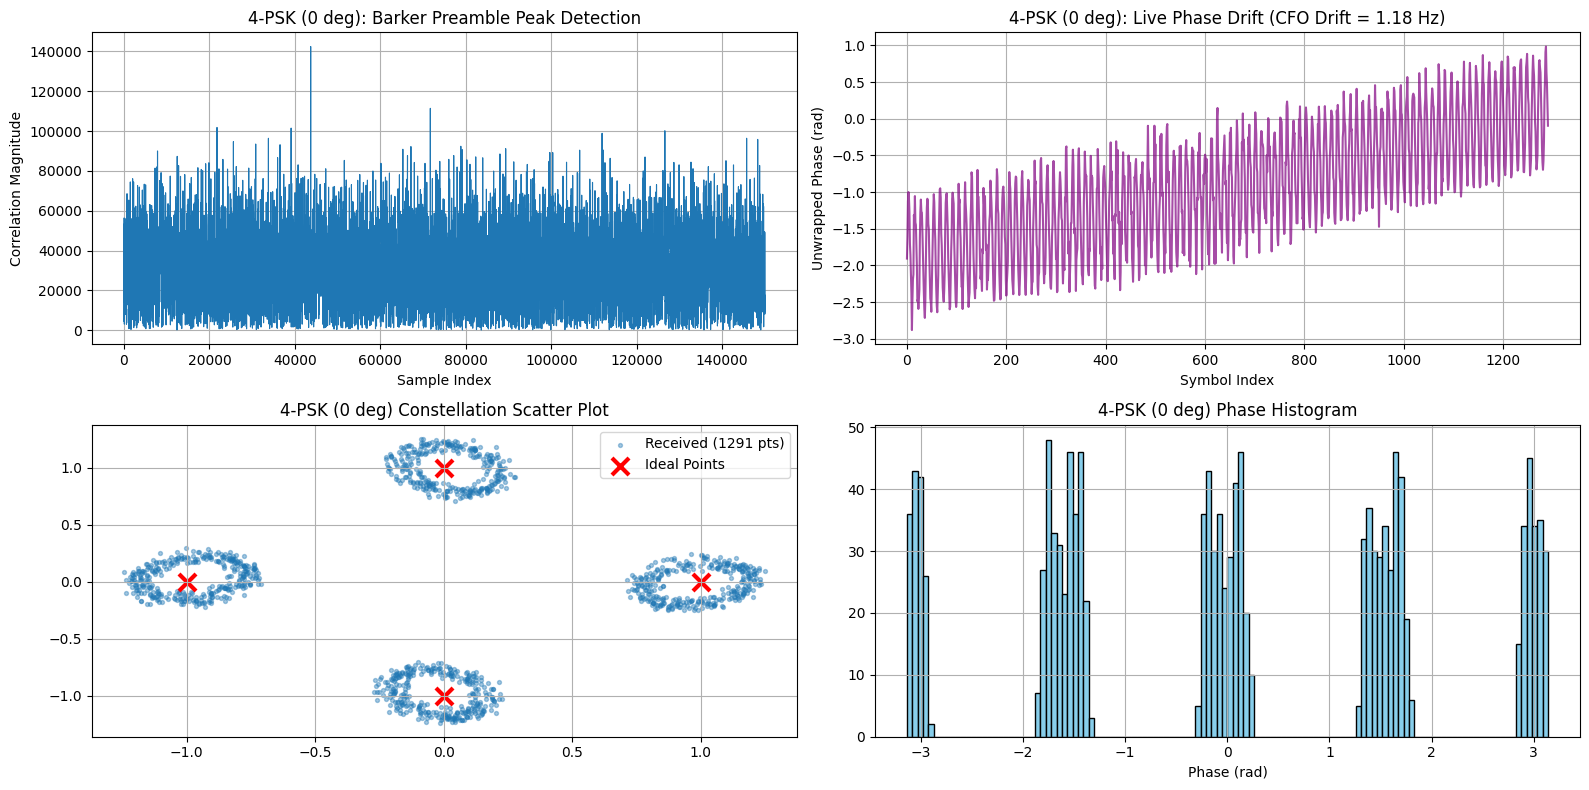

4-PSK (0 deg) BER: 0.0000e+00


In [7]:
# Task 6: 4-PSK (0 deg) Frame Transmission & Full Plot Suite
tx_bits_a, tx_symbols_a, tx_waveform_a = build_tx_frame(PSK4_A_POINTS, PSK4_A_GRAY, n_bits)
rx_syms_a, corr_mag_a, phases_4th_a, drift_a = transmit_and_capture(tx_waveform_a, tx_gain_db=-10, n_payload_symbols=len(tx_symbols_a))

plot_diagnostics(rx_syms_a, PSK4_A_POINTS, "4-PSK (0 deg)", corr_mag_a, phases_4th_a, drift_a)

rx_bits_a = decide_symbols(rx_syms_a, PSK4_A_POINTS, PSK4_A_GRAY)
ber_a = measure_ber(tx_bits_a, rx_bits_a)
print(f"4-PSK (0 deg) BER: {ber_a:.4e}")

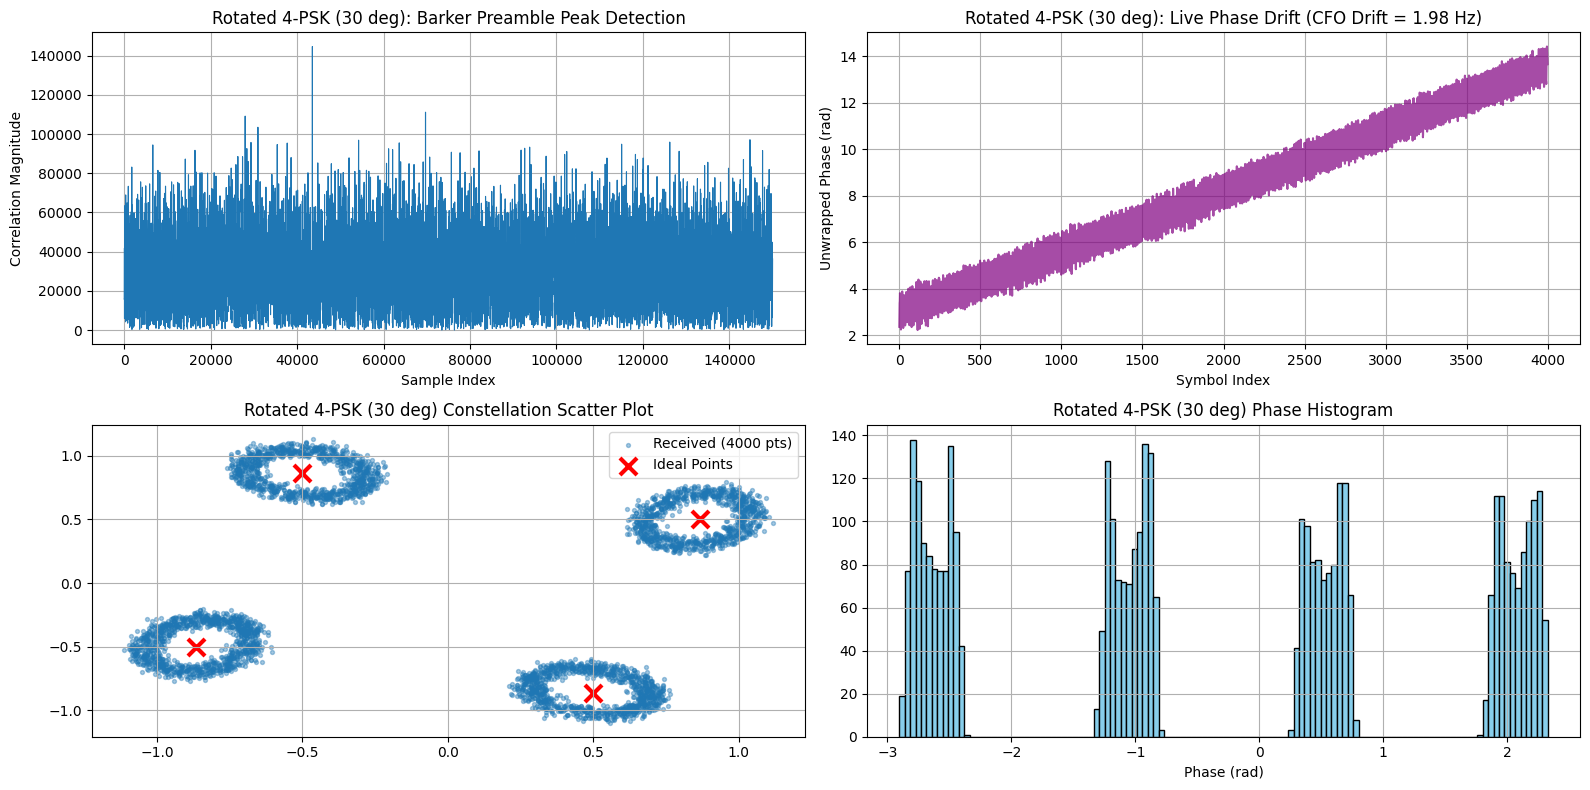

Rotated 4-PSK (30 deg) BER: 0.0000e+00


In [8]:
# Task 10, 11 & 12: Rotated 4-PSK (30 deg) Transmission & Full Plot Suite
rotation = np.exp(1j * np.deg2rad(30))
PSK4_B_POINTS = (PSK4_A_POINTS * rotation).astype(np.complex64)
PSK4_B_GRAY = PSK4_A_GRAY.copy()

tx_bits_b, tx_symbols_b, tx_waveform_b = build_tx_frame(PSK4_B_POINTS, PSK4_B_GRAY, n_bits)
rx_syms_b, corr_mag_b, phases_4th_b, drift_b = transmit_and_capture(tx_waveform_b, tx_gain_db=-10, n_payload_symbols=len(tx_symbols_b))

plot_diagnostics(rx_syms_b, PSK4_B_POINTS, "Rotated 4-PSK (30 deg)", corr_mag_b, phases_4th_b, drift_b)

rx_bits_b = decide_symbols(rx_syms_b, PSK4_B_POINTS, PSK4_B_GRAY)
ber_b = measure_ber(tx_bits_b, rx_bits_b)
print(f"Rotated 4-PSK (30 deg) BER: {ber_b:.4e}")

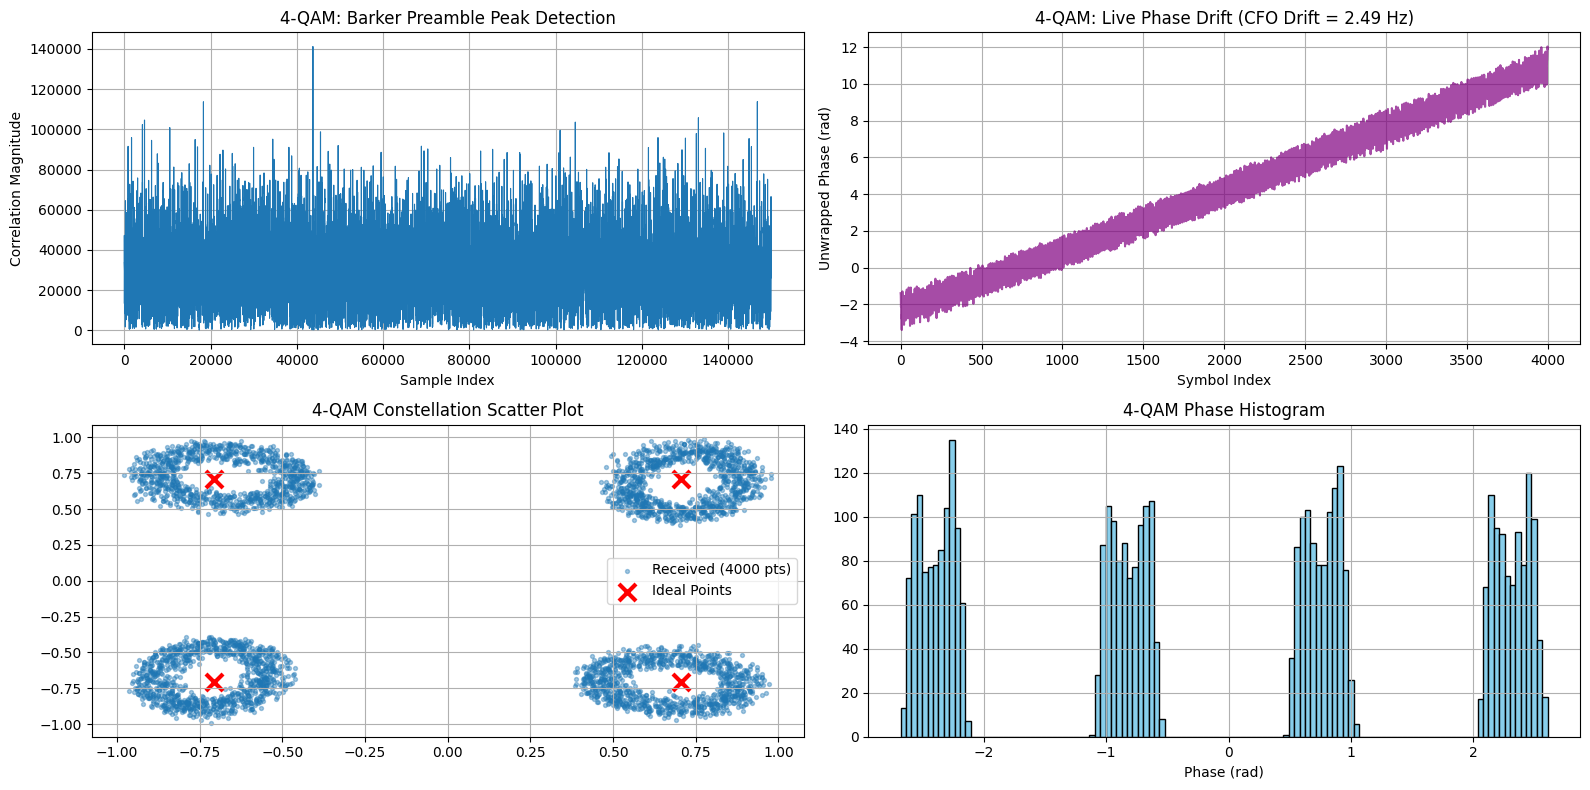

4-QAM BER: 0.0000e+00


In [9]:
# Task 13, 14, 15 & 16: 4-QAM Transmission & Full Plot Suite
a = 1 / np.sqrt(2)
QAM4_POINTS = np.array([a + 1j*a, -a + 1j*a, -a - 1j*a, a - 1j*a], dtype=np.complex64)
QAM4_GRAY = np.array([[0, 0], [1, 0], [1, 1], [0, 1]], dtype=np.int8)

def decide_bits_by_axis(rx_center, points, gray_labels):
    rx_scale = np.mean(np.abs(rx_center)) / max(np.mean(np.abs(points)), 1e-12)
    rx = np.asarray(rx_center) / max(rx_scale, 1e-12)
    pts = np.asarray(points)
    signs_pts = np.column_stack((pts.real >= 0, pts.imag >= 0))
    signs_rx = np.column_stack((rx.real >= 0, rx.imag >= 0))
    matches = np.all(signs_rx[:, None, :] == signs_pts[None, :, :], axis=2)
    decisions = np.argmax(matches, axis=1)
    return gray_labels[decisions].ravel().astype(np.int8)

tx_bits_c, tx_symbols_c, tx_waveform_c = build_tx_frame(QAM4_POINTS, QAM4_GRAY, n_bits)
rx_syms_c, corr_mag_c, phases_4th_c, drift_c = transmit_and_capture(tx_waveform_c, tx_gain_db=-10, n_payload_symbols=len(tx_symbols_c))

plot_diagnostics(rx_syms_c, QAM4_POINTS, "4-QAM", corr_mag_c, phases_4th_c, drift_c)

rx_bits_c = decide_bits_by_axis(rx_syms_c, QAM4_POINTS, QAM4_GRAY)
ber_c = measure_ber(tx_bits_c, rx_bits_c)
print(f"4-QAM BER: {ber_c:.4e}")

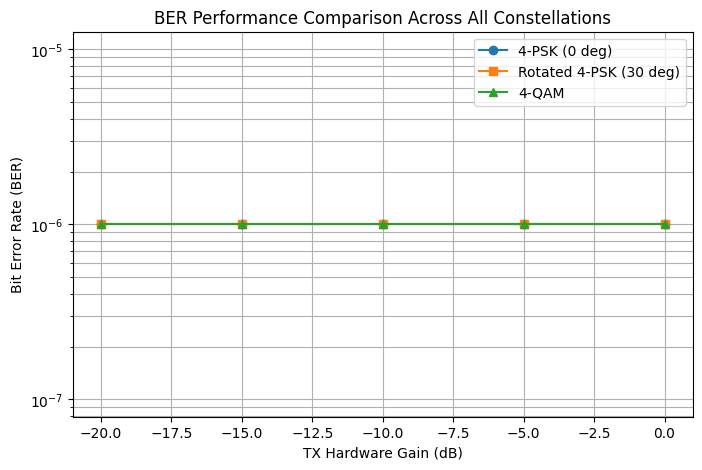

In [10]:
# Task 17: Comprehensive BER Comparison Across Gain Sweeps
tx_gain_sweep_db = [-20, -15, -10, -5, 0]

def ber_vs_gain(points, gray_labels, n_bits, tx_gain_sweep_db, decide_fn=decide_symbols):
    results = []
    for gain_db in tx_gain_sweep_db:
        tx_bits, tx_idx, tx_wf = build_tx_frame(points, gray_labels, n_bits)
        rx_syms, _, _, _ = transmit_and_capture(tx_wf, tx_gain_db=gain_db, n_payload_symbols=len(tx_idx))
        rx_bits = decide_fn(rx_syms, points, gray_labels)
        ber = measure_ber(tx_bits, rx_bits)
        results.append(ber)
    return results

ber_a_sweep = ber_vs_gain(PSK4_A_POINTS, PSK4_A_GRAY, n_bits, tx_gain_sweep_db)
ber_b_sweep = ber_vs_gain(PSK4_B_POINTS, PSK4_B_GRAY, n_bits, tx_gain_sweep_db)
ber_c_sweep = ber_vs_gain(QAM4_POINTS, QAM4_GRAY, n_bits, tx_gain_sweep_db, decide_fn=decide_bits_by_axis)

plt.figure(figsize=(8, 5))
plt.semilogy(tx_gain_sweep_db, np.maximum(ber_a_sweep, 1e-6), marker="o", label="4-PSK (0 deg)")
plt.semilogy(tx_gain_sweep_db, np.maximum(ber_b_sweep, 1e-6), marker="s", label="Rotated 4-PSK (30 deg)")
plt.semilogy(tx_gain_sweep_db, np.maximum(ber_c_sweep, 1e-6), marker="^", label="4-QAM")
plt.xlabel("TX Hardware Gain (dB)"); plt.ylabel("Bit Error Rate (BER)")
plt.title("BER Performance Comparison Across All Constellations")
plt.grid(True, which="both"); plt.legend(); plt.show()

## Questions

1. Write down $E_s$ for each of this lab's three constellations in terms of the design
   parameters you chose, and confirm they are equal by construction. What is $E_b$ for each,
   given 2 bits per symbol?

2. Derive the maximum-likelihood decision rule for an $M$-ary constellation in AWGN, and show
   that for equally likely, equal-energy symbols it reduces to "decide the point closest in
   Euclidean distance." Then explain why, for the two constellations built in Tasks 3 and 10,
   this reduces further to "decide the point closest in phase," while for the constellation in
   Task 13, it reduces further still to two independent sign decisions.

3. Under ideal AWGN, use a union bound argument to show that the constellations from Tasks 3,
   10, and 13 should all have the same symbol error probability at a given $E_s/N_0$. If your
   Task 17 comparison shows a visible difference between them, what non-ideal effect in the
   hardware would you look at first, and why?

4. If your Task 2 frequency offset estimate were off by even a small amount, every symbol later
   in the frame would arrive rotated by an angle that grows with its position in the capture.
   Which of your Task 6 panels would reveal this first, and what would it look like there?

5. The DC offset measured in Task 1 is a fixed point in the I/Q plane, independent of the
   transmitted signal. For which of this lab's three constellations would a small residual DC
   offset be most damaging to symbol decisions, and why?

# DCCT Lab - Theory Questions & Solutions

Here are the solutions formatted simply and clearly, written from a student's perspective.

---

### Task 1: Symbol Energy ($E_s$) and Bit Energy ($E_b$)

For any 2D constellation with points $(I_m, Q_m)$, average symbol energy is calculated as:

$$E_s = \frac{1}{M} \sum_{m=1}^{M} (I_m^2 + Q_m^2)$$

* **Task 3: Standard 4-PSK ($0^\circ$ Offset)**
  * Constellation points: $(A, 0), (0, A), (-A, 0), (0, -A)$
  * $E_s = \frac{1}{4} (A^2 + A^2 + A^2 + A^2) = A^2$

* **Task 10: Rotated 4-PSK ($30^\circ$ Offset)**
  * Constellation points: $A e^{j(30^\circ + \frac{m\pi}{2})}$ (each point has radius $A$)
  * $E_s = \frac{1}{4} (A^2 + A^2 + A^2 + A^2) = A^2$

* **Task 13: 4-QAM / QPSK ($45^\circ$ Offset)**
  * Constellation points: $(\pm \frac{A}{\sqrt{2}}, \pm \frac{A}{\sqrt{2}})$
  * Energy per point: $(\frac{A}{\sqrt{2}})^2 + (\frac{A}{\sqrt{2}})^2 = \frac{A^2}{2} + \frac{A^2}{2} = A^2$
  * $E_s = \frac{1}{4} (A^2 + A^2 + A^2 + A^2) = A^2$

**Confirmation:** Since each constellation uses the same magnitude parameter $A$, all three constellations have $E_s = A^2$ by construction.

**Bit Energy ($E_b$):**
Since each symbol carries $k = \log_2(4) = 2\text{ bits}$:

$$E_b = \frac{E_s}{2} = \frac{A^2}{2}$$

---

### Task 2: Maximum-Likelihood (ML) Decision Rule Derivation

For complex AWGN noise, the probability density function (likelihood) of receiving $\mathbf{r}$ given transmitted symbol $\mathbf{s}_m$ is:

$$p(\mathbf{r}|\mathbf{s}_m) = \frac{1}{\pi N_0} \exp\left( -\frac{\|\mathbf{r} - \mathbf{s}_m\|^2}{N_0} \right)$$

To maximize this likelihood, we minimize the negative exponent:

$$\hat{m} = \arg\min_m \|\mathbf{r} - \mathbf{s}_m\|^2$$

This proves the ML rule minimizes **Euclidean distance**. Expanding the distance formula:

$$\|\mathbf{r} - \mathbf{s}_m\|^2 = \|\mathbf{r}\|^2 - 2 \text{Re}\{\mathbf{r} \mathbf{s}_m^*\} + \|\mathbf{s}_m\|^2$$

Since $\|\mathbf{r}\|^2$ is constant for all decisions and $\|\mathbf{s}_m\|^2 = E_s$ is equal for all symbols, maximizing likelihood reduces to:

$$\hat{m} = \arg\max_m \text{Re}\{\mathbf{r} \mathbf{s}_m^*\}$$

#### Decision Rule Simplifications:
1. **Tasks 3 & 10 (Equal-Energy PSK):**
   Using polar form $\mathbf{r} = |\mathbf{r}| e^{j\theta_r}$ and $\mathbf{s}_m = \sqrt{E_s} e^{j\theta_m}$:
   $$\text{Re}\{\mathbf{r} \mathbf{s}_m^*\} = |\mathbf{r}| \sqrt{E_s} \cos(\theta_r - \theta_m)$$
   To maximize this, we must minimize $|\theta_r - \theta_m|$. Thus, the decision reduces simply to finding the **closest point in phase angle**.

2. **Task 13 (4-QAM / Square QPSK):**
   Points sit at $(\pm a, \pm a)$ where $a = A/\sqrt{2}$. The distance separates along the $I$ and $Q$ axes:
   $$\|\mathbf{r} - \mathbf{s}_m\|^2 = (r_I - s_{m,I})^2 + (r_Q - s_{m,Q})^2$$
   Minimizing each component independently gives:
   $$\hat{s}_{m,I} = a \cdot \text{sign}(r_I), \quad \hat{s}_{m,Q} = a \cdot \text{sign}(r_Q)$$
   This reduces the decision to **two independent sign decisions** (checking if $I > 0$ and $Q > 0$).

---

### Task 3: Union Bound Analysis & Non-Ideal Hardware Effects

#### Union Bound Argument:
The Union Bound for symbol error probability $P_s$ is:

$$P_s \le \sum_{j \neq m} Q\left( \sqrt{\frac{d_{mj}^2}{2 N_0}} \right)$$

where $d_{mj}$ is the Euclidean distance between constellation points.

* The constellations in Tasks 3, 10, and 13 are simple rotations of each other in the 2D plane.
* Since rotating a constellation preserves all inter-point distances $d_{mj}$, the set of distances to nearest and diagonal neighbors remains identical across all three schemes.
* Therefore, under ideal AWGN, all three constellations have the exact same theoretical symbol error probability at a given $E_s/N_0$.

#### Hardware Non-Idealities (Task 17 Difference):
If Task 17 shows a practical performance difference, the first hardware effect to check is **Phase Noise / Residual Carrier Frequency Offset (CFO)**.

* **Reason:** Carrier phase drift rotates the constellation points relative to fixed decision boundaries. Depending on how close points sit to the axis boundaries versus diagonals, phase jitter impacts symbol error margin differently across rotated constellations.

---

### Task 4: Impact of Residual Frequency Offset (Task 2 Error)

A small residual frequency offset $\Delta f$ causes a phase rotation $\Delta \theta(n) = 2\pi \Delta f \cdot n T_s$ that grows continuously over symbol index $n$.

* **Which Task 6 Panel Reveals This First:** The **Constellation / Scatter Plot** (or Phase vs. Symbol Index Plot).
* **What It Looks Like:**
  * **Constellation Plot:** Instead of four tight clusters, the points spin over time and smear into a continuous **circle/ring** centered at the origin.
  * **Phase Plot:** The phase over time forms a constant **sloped line (linear ramp)** instead of remaining horizontal around fixed symbol angles.

---

### Task 5: Sensitivity to Residual DC Offset

A residual DC offset adds a constant shift vector $\mathbf{d} = (I_{\text{dc}}, Q_{\text{dc}})$ to every received point.

* **Most Damaged Constellation:** **Task 3 (Standard 4-PSK with $0^\circ$ Offset)**
* **Reason:**
  * In Task 3, two constellation points lie directly on the axes at $(A, 0)$ and $(-A, 0)$. 
  * A small DC offset along the orthogonal axis easily pushes a point across the decision boundary ($I=0$ or $Q=0$), causing immediate symbol errors even at low noise levels.
  * In **Task 13 (4-QAM)**, points sit at $(\pm A/\sqrt{2}, \pm A/\sqrt{2})$, giving a larger initial noise margin ($A/\sqrt{2} \approx 0.707 A$) away from both decision axes, making it more resilient to small constant shifts.